# PHYS 434 — Lab 5 Project Proposal
**Joe Guanyu**

## Project B: Driver Control & Kinematic-Aerodynamic Dynamics

### Data
I will use vehicle telemetry from Assetto Corsa Competizione, shared with my lab partner, Duran Wang. The available data include time, steering angle, speed, yaw rate, and longitudinal acceleration. The initial dataset is a Porsche 718 Cayman GT4 MR session at Red Bull Ring. We also plan to collect Audi R8 GT3 and GT4 data at Barcelona to compare different vehicles.

### Research question
I want to investigate how driver steering input, vehicle speed, and braking or acceleration relate to changes in the car's turning motion. Can PySINDy identify a simple model that predicts yaw acceleration, and under what driving conditions does the model work well or break down? If the additional vehicle data are available, I would also like to explore differences in steering response between GT3 and GT4 cars, including possible effects of aerodynamic loading.

### Initial plan
1. **Explore and prepare the data.** I will plot the main channels, check their units and missing values, and identify useful laps or cornering sections. I will explore smoothing the yaw-rate signal before estimating yaw acceleration, since numerical differentiation can amplify noise.
2. **Try PySINDy.** I will use steering angle, speed, longitudinal acceleration, and current yaw rate to explore models for yaw acceleration. I will try different candidate terms and model settings rather than fix the equation in advance. The aim is to find a relatively simple model that captures the observed response.
3. **Evaluate the results.** I will test predictions on laps or sections that were not used for fitting and examine the residuals. I am interested in whether errors become larger during braking, fast corners, or unusual steering events.
4. **Apply statistical methods from class.** One possible question is whether including speed-dependent steering effects improves predictions compared with a simpler model. The null hypothesis would be that the added terms do not improve prediction performance. I plan to investigate uncertainty and statistical significance while accounting for the fact that nearby time samples are correlated. The exact test will depend on the data and the models we obtain.

### Collaboration
My partner and I will share the telemetry and help each other with data preparation. My Project B focuses on steering input and vehicle speed, while my partner's Project A focuses on measured lateral and longitudinal accelerations. We can compare where the two approaches succeed or fail.

### Initial plot
The code below loads the available Porsche telemetry and plots yaw rate, steering angle, speed, and longitudinal acceleration over time. This gives an initial view of the data and confirms that the main channels needed for my project are available.


Loaded 72,308 timestamped samples from red_bull_ring-porsche_718_cayman_gt4_mr-15-2026.01.04-22.28.csv
Missing measurements: {'ROTY': 0, 'STEERANGLE': 0, 'SPEED': 0, 'G_LON': 0}
Duration: 723.07 s
Median sampling interval: 0.0100 s
Non-increasing time steps: 0


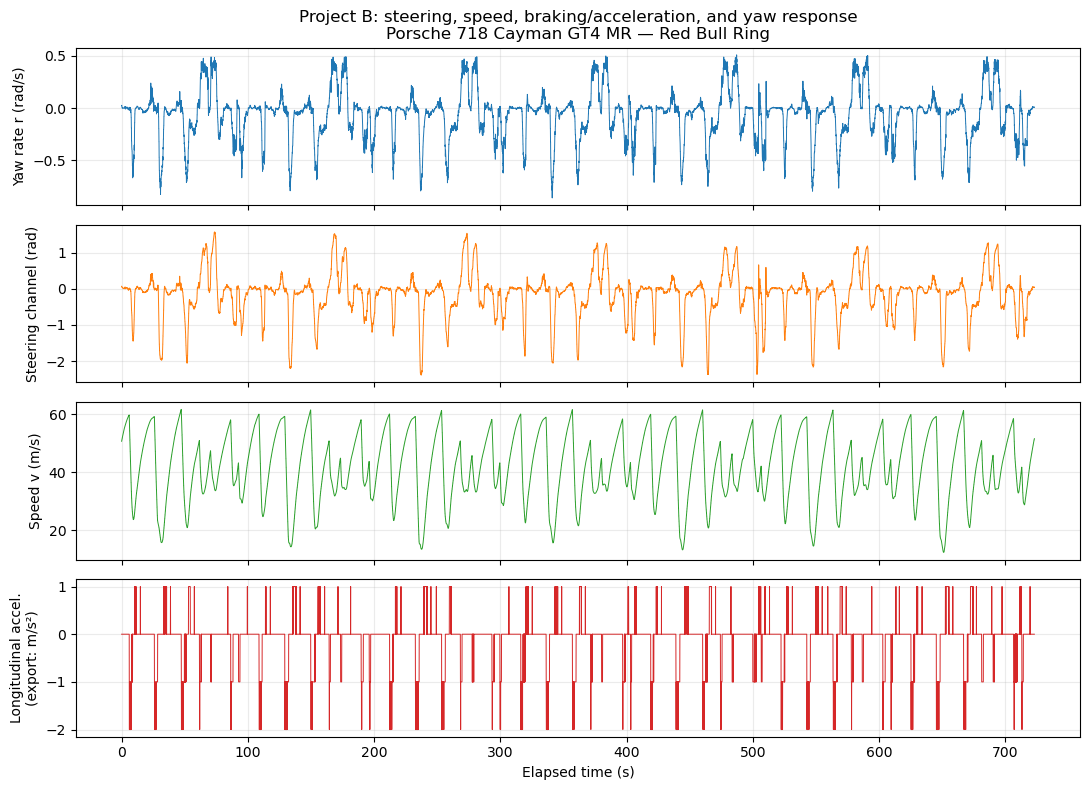

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = Path('red_bull_ring-porsche_718_cayman_gt4_mr-15-2026.01.04-22.28.csv')
with data_path.open(encoding='utf-8-sig') as f:
    for header_row, row in enumerate(csv.reader(f)):
        if row[:4] == ['Time', 'LAP_BEACON', 'G_LAT', 'ROTY']:
            break
    else:
        raise ValueError('Telemetry header not found')

raw = pd.read_csv(data_path, skiprows=header_row, low_memory=False)
channels = ['Time', 'ROTY', 'STEERANGLE', 'SPEED', 'G_LON']
data = raw[channels].apply(pd.to_numeric, errors='coerce')
data = data.dropna(subset=['Time']).reset_index(drop=True)
print(f'Loaded {len(data):,} timestamped samples from {data_path.name}')
print('Missing measurements:', data.drop(columns='Time').isna().sum().to_dict())
dt = np.diff(data['Time'].to_numpy())
print(f'Duration: {data.Time.iloc[-1] - data.Time.iloc[0]:.2f} s')
print(f'Median sampling interval: {np.median(dt):.4f} s')
print(f'Non-increasing time steps: {np.sum(dt <= 0)}')

time = data['Time'] - data['Time'].iloc[0]
series = [np.deg2rad(data['ROTY']), np.deg2rad(data['STEERANGLE']),
          data['SPEED'] / 3.6, data['G_LON']]
labels = ['Yaw rate r (rad/s)', 'Steering channel (rad)',
          'Speed v (m/s)', 'Longitudinal accel.\n(export: m/s²)']
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, values, label, color in zip(axes, series, labels,
                                  ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']):
    ax.plot(time, values, linewidth=0.7, color=color)
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)
axes[0].set_title('Project B: steering, speed, braking/acceleration, and yaw response\nPorsche 718 Cayman GT4 MR — Red Bull Ring')
axes[-1].set_xlabel('Elapsed time (s)')
fig.tight_layout()
plt.show()

**Initial checks:** The file contains 72,308 timestamped samples spanning 723.07 s, with a median interval of 0.0100 s (100 Hz). Yaw rate, steering angle, speed, and longitudinal acceleration have no missing measurements, and timestamps are strictly increasing. The initial plot displays these four Project B channels. Derivative estimation, model fitting, and comparison with additional vehicle sessions will follow in Labs 6–8.